# DSCI 552 — Homework 4
**Name:** Long Zhang  
**GitHub Username:** zl535992549-cell   
**USC ID:** 8768388438  

In [ ]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.base import clone
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Inconsistent values: penalty=l1.*', category=UserWarning)
warnings.filterwarnings('ignore', message='The least populated class.*')
rng = np.random.default_rng(42)
DATA_DIR = Path('data/AReM')
ACTIVITIES = ['bending1','bending2','cycling','lying','sitting','standing','walking']
SERIES_NAMES = ['avg_rss12','var_rss12','avg_rss13','var_rss13','avg_rss23','var_rss23']
cv = StratifiedKFold(5, shuffle=True, random_state=42)
assert DATA_DIR.is_dir(), 'Missing data/AReM folder'

def best_cv(factory, labels, values):
    rows = []
    for l, param in values:
        score = cross_val_score(factory(param), X_train_by_l[l], labels, cv=cv).mean()
        rows.append((l, param, score))
    return pd.DataFrame(rows, columns=['l','param','cv_accuracy']).sort_values(
        ['cv_accuracy','l','param'], ascending=[False,True,True]).iloc[0]

def plot_roc(y, probs, classes, title):
    fig, ax = plt.subplots(figsize=(7,5))
    for j, name in enumerate(classes):
        binary = (np.asarray(y) == name).astype(int)
        fpr, tpr, _ = roc_curve(binary, probs[:,j])
        ax.plot(fpr, tpr, label=f'{name}: {roc_auc_score(binary,probs[:,j]):.2f}')
    ax.plot([0,1],[0,1],'k--',alpha=.3)
    ax.set(xlabel='False positive rate',ylabel='True positive rate',title=title)
    ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

def plot_cm(y, pred, labels, title):
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=labels, xticks_rotation=35, cmap='Blues', colorbar=False)
    plt.title(title); plt.tight_layout(); plt.show()

## 1. Time Series Features

### 1(a). Load and Clean Data

In [ ]:
def read_arem_csv(path):
    rows = []
    for line in path.read_text(encoding='utf-8-sig').splitlines():
        if not line.strip() or line.lstrip().startswith('#'):
            continue
        parts = re.split(r'[,\s]+', line.strip().rstrip(','))
        if len(parts) == 7:
            rows.append([float(x) for x in parts])
    df = pd.DataFrame(rows, columns=['time'] + SERIES_NAMES).set_index('time')
    df = df.reindex(np.arange(0,120000,250))
    missing = int(df[SERIES_NAMES[0]].isna().sum())
    return df.interpolate(limit_direction='both').to_numpy(), missing

records = []
for activity in ACTIVITIES:
    for path in sorted((DATA_DIR/activity).glob('dataset*.csv'), key=lambda p: int(p.stem[7:])):
        signal, missing = read_arem_csv(path)
        assert signal.shape == (480,6)
        records.append(dict(activity=activity,number=int(path.stem[7:]),signals=signal,missing=missing))
print('Instances:',len(records),'| Missing timestamps:',sum(r['missing'] for r in records))

Instances: 88 | Missing timestamps: 1


**Answer:** I fixed formatting issues and filled missing values.

### 1(b). Train/Test Split

In [ ]:
for r in records:
    r['test'] = r['number'] <= (2 if r['activity'].startswith('bending') else 3)
train_records = [r for r in records if not r['test']]
test_records = [r for r in records if r['test']]
assert (len(train_records),len(test_records)) == (69,19)

def labels(items):
    return np.array([r['activity'] for r in items])

y_train_multi, y_test_multi = labels(train_records), labels(test_records)
y_train_binary = np.array([int(x.startswith('bending')) for x in y_train_multi])
y_test_binary = np.array([int(x.startswith('bending')) for x in y_test_multi])
print('Train:',len(train_records),'Test:',len(test_records))
display(pd.DataFrame({'Train':pd.Series(y_train_multi).value_counts(),
                      'Test':pd.Series(y_test_multi).value_counts()}).fillna(0).astype(int))

Train: 69 Test: 19


,Train,Test
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


### 1(c)i. Time-Domain Features

### 1(c)ii. Extract Features

In [ ]:
feature_kinds = ['min','max','mean','median','std','q1','q3']
feature_cols = [f'{kind}{j}' for j in range(1,7) for kind in feature_kinds]

def features(x):
    return np.array([x.min(),x.max(),x.mean(),np.median(x),x.std(ddof=1),*np.quantile(x,[.25,.75])])

summary_features = pd.DataFrame([
    np.concatenate([features(r['signals'][:,j]) for j in range(6)]) for r in records
],columns=feature_cols)
summary_features.insert(0,'Instance',range(1,len(records)+1))
summary_features['activity'] = labels(records)
display(summary_features.head().round(3))

,Instance,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,median2,std2,q12,q32,min3,max3,mean3,median3,std3,q13,q33,min4,max4,mean4,median4,std4,q14,q34,min5,max5,mean5,median5,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36,activity
0,1,37.25,45.00,40.625,40.50,1.477,39.25,42.00,0.0,1.30,0.359,0.43,0.323,0.00,0.50,4.0,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.00,1.120,27.25,38.25,34.311,35.0,2.188,33.000,36.00,0.0,1.92,0.571,0.43,0.583,0.0,1.30,bending1
1,2,38.00,45.67,42.813,42.50,1.436,42.00,43.67,0.0,1.22,0.372,0.47,0.289,0.00,0.50,2.0,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.00,1.145,27.67,38.50,33.025,33.0,1.995,32.000,34.50,0.0,3.11,0.571,0.43,0.601,0.0,1.30,bending1
2,3,35.00,47.40,43.954,44.33,1.559,43.00,45.00,0.0,1.70,0.426,0.47,0.339,0.00,0.50,6.5,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.00,0.830,29.00,38.50,35.588,36.0,2.000,35.362,36.50,0.0,1.79,0.493,0.43,0.514,0.0,0.94,bending1
3,4,33.00,47.75,42.180,43.50,3.671,39.15,45.00,0.0,3.00,0.696,0.50,0.631,0.00,1.12,8.5,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.43,1.300,20.00,38.67,33.494,35.0,3.849,30.458,36.33,0.0,2.18,0.614,0.50,0.524,0.0,1.00,bending1
4,5,33.00,45.75,41.678,41.75,2.243,41.33,42.75,0.0,2.83,0.536,0.50,0.405,0.43,0.71,3.0,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.43,1.120,23.67,37.50,29.857,30.0,2.411,28.458,31.25,0.0,1.79,0.383,0.43,0.389,0.0,0.50,bending1


### 1(c)iii. SD and 90% Bootstrap CI

In [ ]:
x = summary_features[feature_cols].to_numpy()
bootstrap = np.std(x[rng.integers(len(x),size=(2000,len(x)))],axis=1,ddof=1)
sd_summary = pd.DataFrame({'feature':feature_cols,'sample_sd':x.std(axis=0,ddof=1),
                           'ci90_lower':np.percentile(bootstrap,5,axis=0),
                           'ci90_upper':np.percentile(bootstrap,95,axis=0)})
display(sd_summary.round(3))

,feature,sample_sd,ci90_lower,ci90_upper
0,min1,9.570,8.214,10.775
1,max1,4.394,3.334,5.316
2,mean1,5.336,4.709,5.890
3,median1,5.440,4.768,6.013
4,std1,1.772,1.562,1.948
5,q11,6.154,5.557,6.660
6,q31,5.139,4.330,5.860
7,min2,0.000,0.000,0.000
8,max2,5.063,4.619,5.406
9,mean2,1.574,1.401,1.704


### 1(c)iv. Best Features

**Answer:** Minimum, mean, and maximum show the range and average of each series.

## 2. Classification

In [ ]:
def segment_features(items, l):
    names = [f's{j}_part{p}_{k}' for j in range(1,7) for p in range(1,l+1)
             for k in ('min','mean','max')]
    rows = []
    for r in items:
        rows.append([v for j in range(6) for part in np.array_split(r['signals'][:,j],l)
                     for v in (part.min(),part.mean(),part.max())])
    return pd.DataFrame(rows,columns=names)

X_train_by_l = {l:segment_features(train_records,l) for l in range(1,21)}
X_test_by_l = {l:segment_features(test_records,l) for l in range(1,21)}
print('Feature shapes:',X_train_by_l[1].shape,X_train_by_l[20].shape)

Feature shapes: (69, 18) (69, 360)


### 2(a)i. Scatter Plots

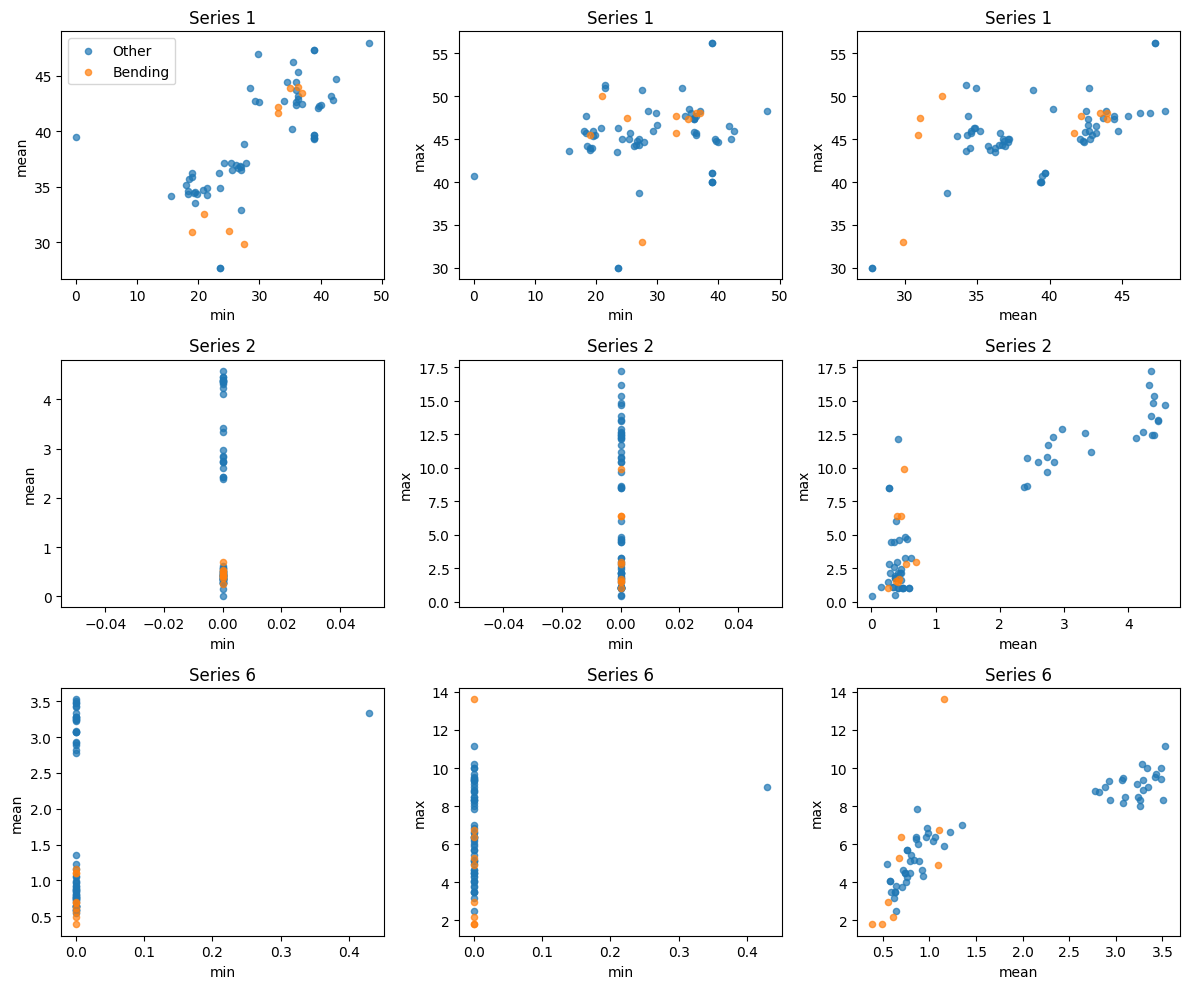

In [ ]:
pairs = [('min','mean'),('min','max'),('mean','max')]
fig, axes = plt.subplots(3,3,figsize=(12,10))
for i,series in enumerate((1,2,6)):
    for j,(a,b) in enumerate(pairs):
        ax = axes[i,j]
        for label,color in ((0,'tab:blue'),(1,'tab:orange')):
            x = X_train_by_l[1].loc[y_train_binary==label]
            ax.scatter(x[f's{series}_part1_{a}'],x[f's{series}_part1_{b}'],
                       s=20,alpha=.7,c=color,label=('Other' if label==0 else 'Bending'))
        ax.set(xlabel=a,ylabel=b,title=f'Series {series}')
axes[0,0].legend(); fig.tight_layout(); plt.show()

### 2(a)ii. Scatter Plot Comparison

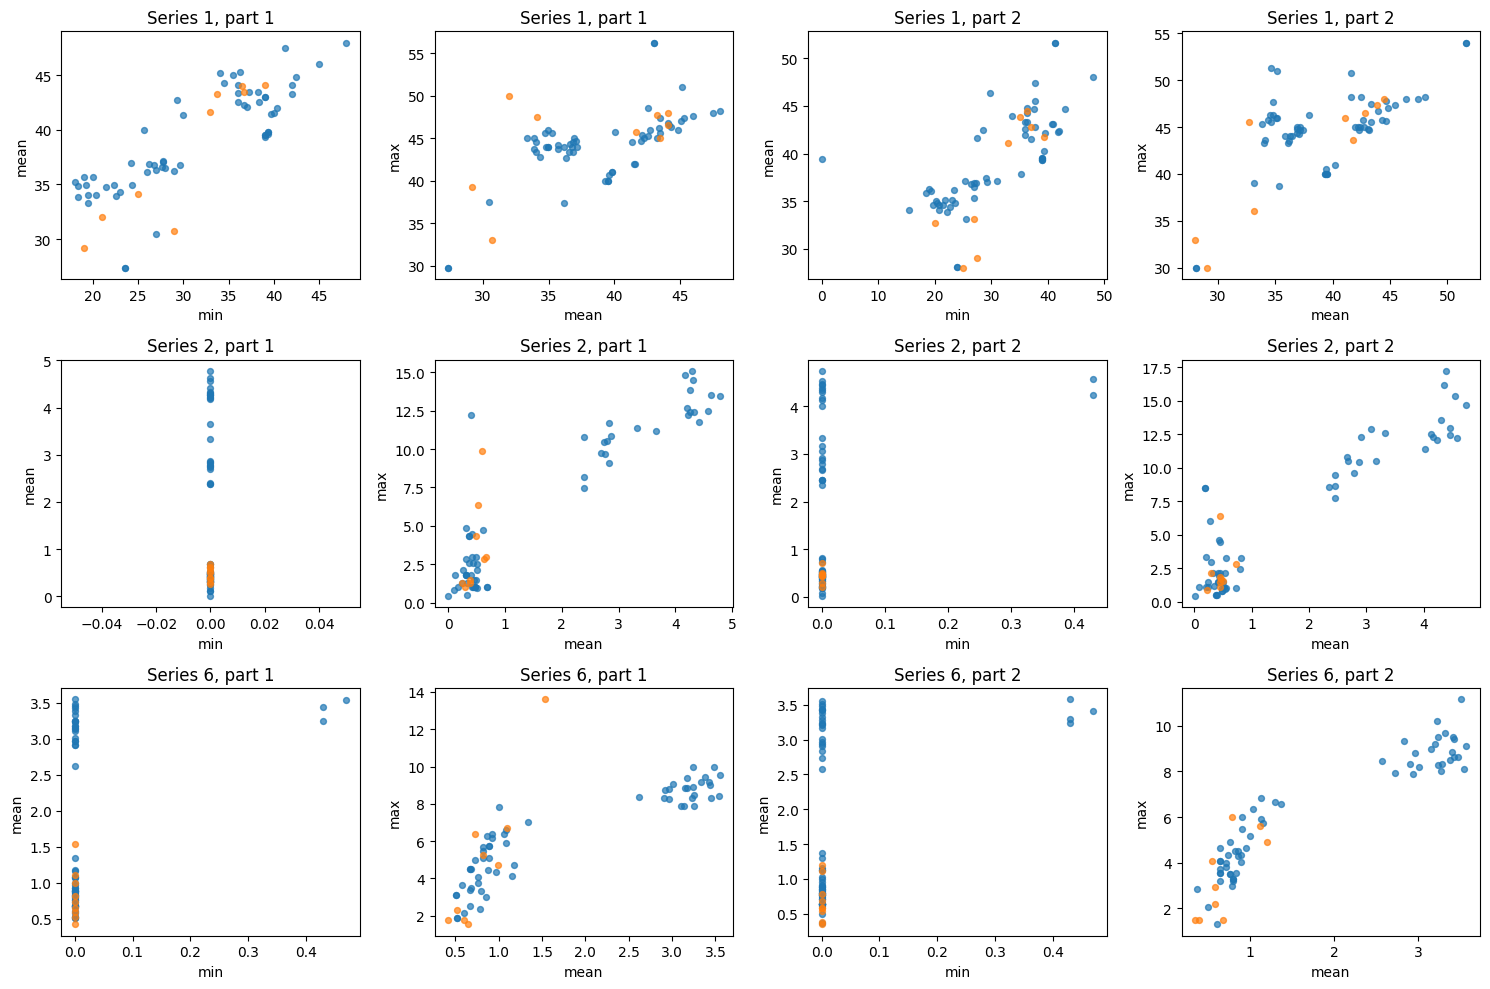

In [ ]:
fig, axes = plt.subplots(3,4,figsize=(15,10))
for i,series in enumerate((1,2,6)):
    for part in (1,2):
        for j,(a,b) in enumerate((('min','mean'),('mean','max'))):
            ax = axes[i,(part-1)*2+j]
            for label,color in ((0,'tab:blue'),(1,'tab:orange')):
                x = X_train_by_l[2].loc[y_train_binary==label]
                ax.scatter(x[f's{series}_part{part}_{a}'],x[f's{series}_part{part}_{b}'],s=18,alpha=.7,c=color)
            ax.set(xlabel=a,ylabel=b,title=f'Series {series}, part {part}')
fig.tight_layout(); plt.show()

**Answer:** Splitting into two parts shows more detail, but the classes still overlap.

### 2(a)iii. Logistic Regression with 5-Fold CV

In [ ]:
def plain_lr():
    return LogisticRegression(C=10000,solver='liblinear',max_iter=350)

def rfe_model(p):
    return make_pipeline(StandardScaler(),RFE(plain_lr(),n_features_to_select=p,step=.25),plain_lr())

rfe_rows = []
for l in range(1,21):
    for p in (3,6,12):
        score = cross_val_score(rfe_model(p),X_train_by_l[l],y_train_binary,cv=cv).mean()
        rfe_rows.append((l,p,score))
rfe_table = pd.DataFrame(rfe_rows,columns=['l','p','cv_accuracy']).sort_values(
    ['cv_accuracy','p','l'],ascending=[False,True,True])
best_rfe = rfe_table.iloc[0]
best_l_rfe,best_p_rfe = int(best_rfe.l),int(best_rfe.p)
binary_rfe = rfe_model(best_p_rfe).fit(X_train_by_l[best_l_rfe],y_train_binary)
selected_rfe = X_train_by_l[best_l_rfe].columns[binary_rfe.named_steps['rfe'].support_].tolist()
display(rfe_table.head(5).round(4))
print('Best l, p:',best_l_rfe,best_p_rfe,'| Selected:',selected_rfe)

,l,p,cv_accuracy
21,8,3,0.9714
30,11,3,0.9714
7,3,6,0.9714
2,1,12,0.9714
26,9,12,0.9714


Best l, p: 8 3 | Selected: ['s1_part5_mean', 's4_part6_mean', 's5_part2_max']


**Answer:** Right: Select features within each training fold.
Wrong: Select features before cross-validation because it causes data leakage. Stratified CV keeps the class ratios similar.

### 2(a)iv. Training Results

RFE train: accuracy=1.0000, AUC=1.0000


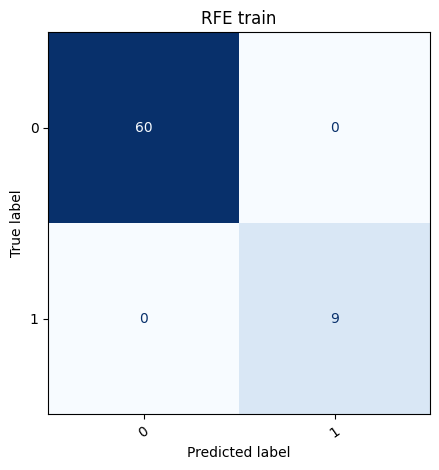

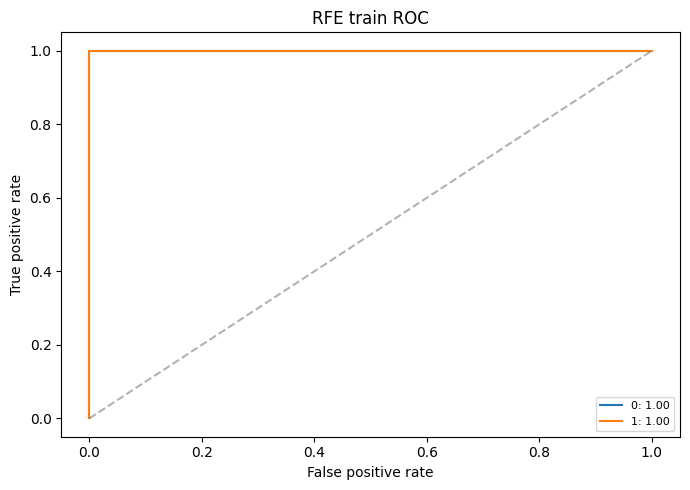

,feature,coefficient,p_value
0,intercept,-113.5351,0.9990
1,s1_part5_mean,-20.2922,0.9994
2,s4_part6_mean,-76.8163,0.9991
3,s5_part2_max,76.3372,0.9991


In [ ]:
def binary_evaluation(y, model, x, title):
    pred, prob = model.predict(x),model.predict_proba(x)[:,1]
    acc, auc = accuracy_score(y,pred),roc_auc_score(y,prob)
    print(f'{title}: accuracy={acc:.4f}, AUC={auc:.4f}')
    plot_cm(y,pred,[0,1],title)
    plot_roc(y,np.column_stack([1-prob,prob]),[0,1],title+' ROC')
    return {'accuracy':acc,'auc':auc},prob

metrics_rfe_train,train_prob_rfe = binary_evaluation(
    y_train_binary,binary_rfe,X_train_by_l[best_l_rfe],'RFE train')
scaled = binary_rfe.named_steps['standardscaler'].transform(X_train_by_l[best_l_rfe])
selected_scaled = scaled[:,binary_rfe.named_steps['rfe'].support_]
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter('always')
    glm_fit = sm.GLM(y_train_binary,sm.add_constant(selected_scaled),family=sm.families.Binomial()).fit()
coef_table = pd.DataFrame({'feature':['intercept']+selected_rfe,
                           'coefficient':glm_fit.params,'p_value':glm_fit.pvalues})
display(coef_table.round(4))
large_beta = np.max(np.abs(glm_fit.params)) > 15
separation_warnings = [str(w.message) for w in fit_warnings if 'separat' in str(w.message).lower()]

### 2(a)v. Test Results

RFE test: accuracy=0.9474, AUC=1.0000


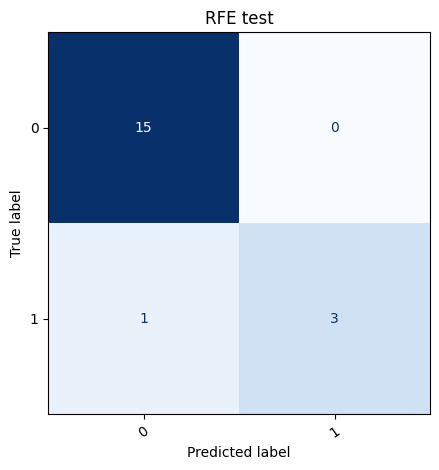

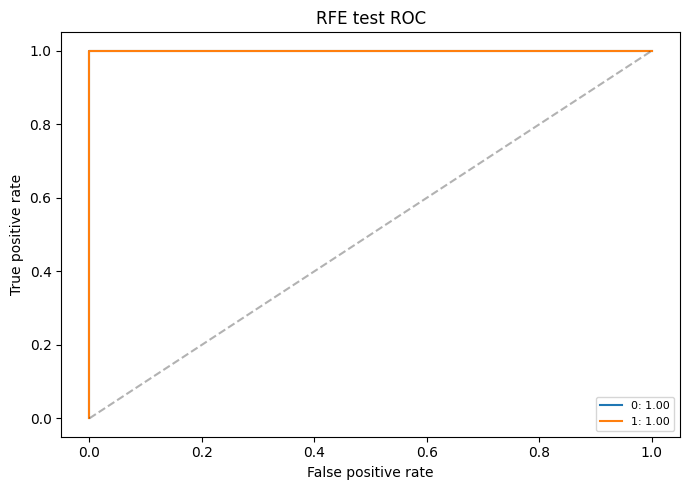

CV accuracy: 0.9714


In [ ]:
metrics_rfe_test,test_prob_rfe = binary_evaluation(
    y_test_binary,binary_rfe,X_test_by_l[best_l_rfe],'RFE test')
print('CV accuracy:',round(best_rfe.cv_accuracy,4))

### 2(a)vi. Separation Check

In [ ]:
extreme = np.mean((train_prob_rfe<1e-4)|(train_prob_rfe>1-1e-4))
print('Extreme probabilities:',round(extreme,3),'| Large coefficients:',bool(large_beta))
print('Possible separation:',bool(extreme>.5 or large_beta or separation_warnings))

Extreme probabilities: 0.928 | Large coefficients: True
Possible separation: True


### 2(a)vii. Class Imbalance

**Answer:** I used oversampling and intercept adjustment.

Case-control train: accuracy=1.0000, AUC=1.0000


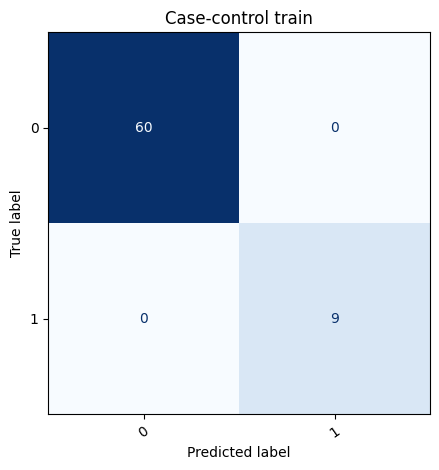

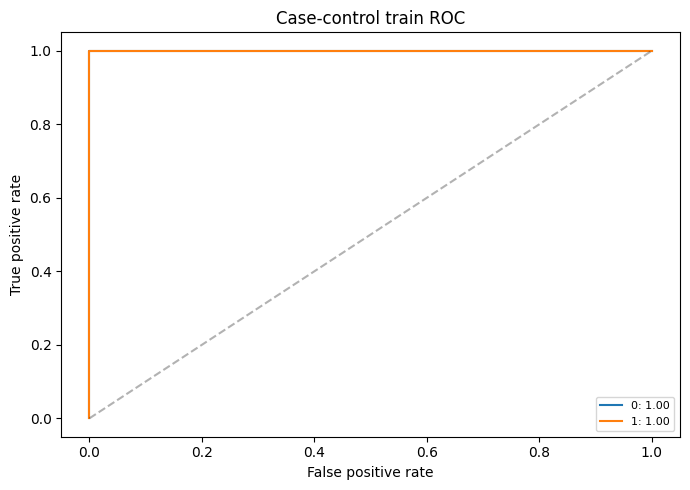

Case-control test accuracy: 0.9473684210526315


In [ ]:
scaler = StandardScaler().fit(X_train_by_l[best_l_rfe][selected_rfe])
x_train = scaler.transform(X_train_by_l[best_l_rfe][selected_rfe])
pos,neg = np.where(y_train_binary==1)[0],np.where(y_train_binary==0)[0]
idx = np.r_[neg,pos,rng.choice(pos,len(neg)-len(pos),replace=True)]
cc_model = plain_lr().fit(x_train[idx],y_train_binary[idx])
real_prior,sample_prior = y_train_binary.mean(),y_train_binary[idx].mean()
cc_model.intercept_ += np.log(real_prior/(1-real_prior))-np.log(sample_prior/(1-sample_prior))
metrics_cc,_ = binary_evaluation(y_train_binary,cc_model,x_train,'Case-control train')
x_test = scaler.transform(X_test_by_l[best_l_rfe][selected_rfe])
print('Case-control test accuracy:',accuracy_score(y_test_binary,cc_model.predict(x_test)))

## 2(b). L1 Logistic Regression

### 2(b)i. 5-Fold CV

I selected `l` and `C` using 5-fold CV.

,l,C,cv_accuracy
46,12,1.0,0.9857
3,1,10.0,0.9714
14,4,1.0,0.9714
42,11,1.0,0.9714
47,12,10.0,0.9714


Nonzero coefficients: 5
L1 test: accuracy=0.9474, AUC=0.9833


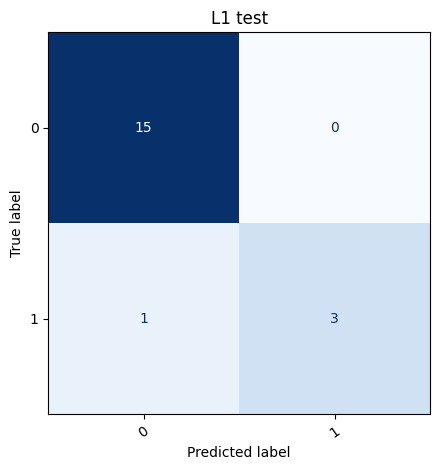

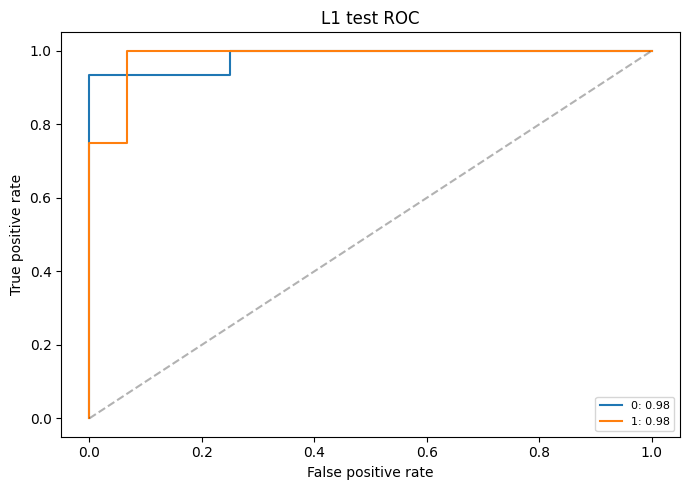

({'accuracy': 0.9473684210526315, 'auc': 0.9833333333333334},
 array([9.96200410e-01, 9.92287007e-01, 9.45508934e-01, 2.03455980e-01,
        6.90196100e-02, 8.51147199e-02, 6.53018478e-02, 2.55066227e-02,
        1.51751972e-03, 6.78039412e-04, 3.16949588e-03, 3.25577432e-02,
        2.40239463e-01, 4.18146299e-02, 5.64747963e-02, 3.36721761e-02,
        3.72699234e-02, 5.01606117e-02, 2.53041594e-02]))

In [ ]:
def l1_binary(c):
    return make_pipeline(StandardScaler(),LogisticRegression(penalty='l1',solver='liblinear',C=c,max_iter=1000))

binary_l1_rows = []
for l in range(1,21):
    for c in (.01,.1,1.,10.):
        binary_l1_rows.append((l,c,cross_val_score(l1_binary(c),X_train_by_l[l],y_train_binary,cv=cv).mean()))
binary_l1_table = pd.DataFrame(binary_l1_rows,columns=['l','C','cv_accuracy']).sort_values(
    ['cv_accuracy','l','C'],ascending=[False,True,True])
best_binary_l1 = binary_l1_table.iloc[0]
l = int(best_binary_l1.l)
model_binary_l1 = l1_binary(best_binary_l1.C).fit(X_train_by_l[l],y_train_binary)
acc_l1_test = accuracy_score(y_test_binary,model_binary_l1.predict(X_test_by_l[l]))
display(binary_l1_table.head(5).round(4))
print('Nonzero coefficients:',np.count_nonzero(model_binary_l1.named_steps['logisticregression'].coef_))
binary_evaluation(y_test_binary,model_binary_l1,X_test_by_l[l],'L1 test')

### 2(b)ii. RFE vs L1

In [ ]:
comparison_binary = pd.DataFrame([
    ['RFE',best_l_rfe,best_rfe.cv_accuracy,metrics_rfe_test['accuracy']],
    ['L1',int(best_binary_l1.l),best_binary_l1.cv_accuracy,acc_l1_test]
],columns=['Method','l','CV accuracy','Test accuracy'])
display(comparison_binary.round(4))

,Method,l,CV accuracy,Test accuracy
0,RFE,8,0.9714,0.9474
1,L1,12,0.9857,0.9474


**Answer:** L1 is easier because it selects features automatically.

## 2(c). Multiclass Classification

### 2(c)i. Multiclass L1 Logistic Regression

I used 5-fold CV to choose `l` and `C`, then evaluated test error, confusion matrix, and ROC/AUC.

,l,C,cv_accuracy
2,1,1.0,0.8846
5,2,1.0,0.8407
26,9,1.0,0.8000
53,18,1.0,0.7846
56,19,1.0,0.7846


Test error: 0.0526


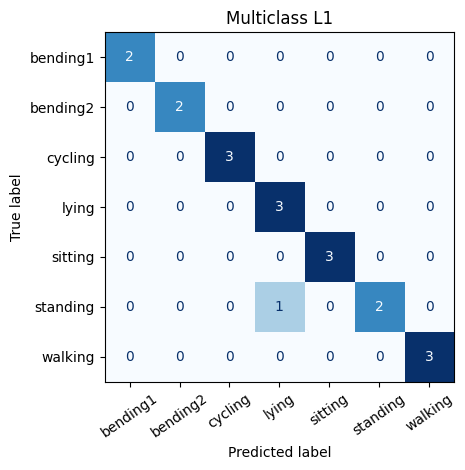

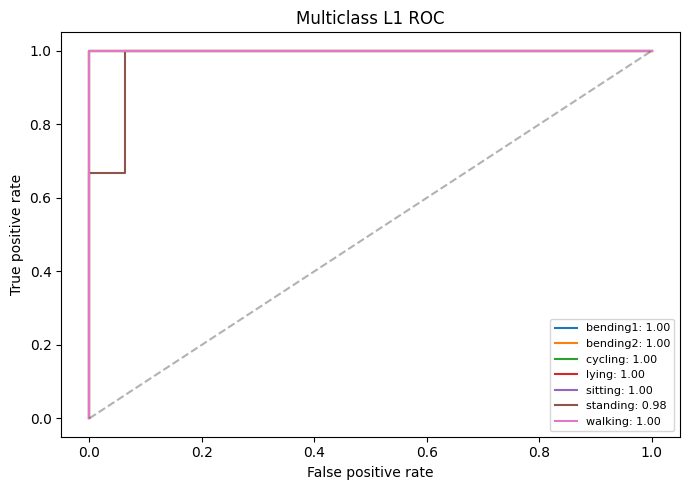

In [ ]:
def multi_lr(c):
    return make_pipeline(StandardScaler(),LogisticRegression(penalty='l1',solver='saga',C=c,
                                                            max_iter=800,tol=.01,random_state=42))

multi_rows = []
for l in range(1,21):
    for c in (.05,.2,1.):
        multi_rows.append((l,c,cross_val_score(multi_lr(c),X_train_by_l[l],y_train_multi,cv=cv).mean()))
multinomial_table = pd.DataFrame(multi_rows,columns=['l','C','cv_accuracy']).sort_values(
    ['cv_accuracy','l','C'],ascending=[False,True,True])
best_multi = multinomial_table.iloc[0]
l = int(best_multi.l)
multi_model = multi_lr(best_multi.C).fit(X_train_by_l[l],y_train_multi)
pred = multi_model.predict(X_test_by_l[l])
prob = multi_model.predict_proba(X_test_by_l[l])
acc_multi = accuracy_score(y_test_multi,pred)
display(multinomial_table.head(5).round(4))
print('Test error:',round(1-acc_multi,4))
plot_cm(y_test_multi,pred,ACTIVITIES,'Multiclass L1')
plot_roc(y_test_multi,prob,multi_model.classes_,'Multiclass L1 ROC')

**ROC:** One-vs-rest AUC is calculated for each class. **Limitation:** `bending2` has only four training samples, so 5-fold CV estimates may be unstable.

### 2(c)ii. Naive Bayes

Gaussian NB: l=1, CV=0.8989, test error=0.1053


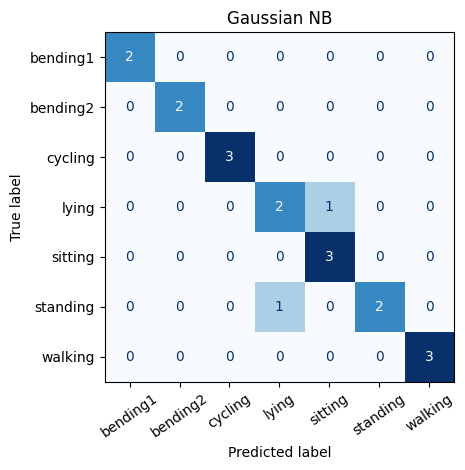

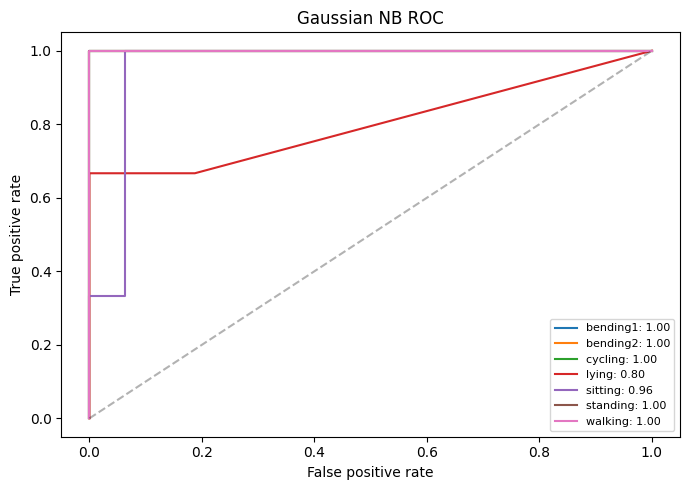

Multinomial NB: l=5, CV=0.7264, test error=0.2105


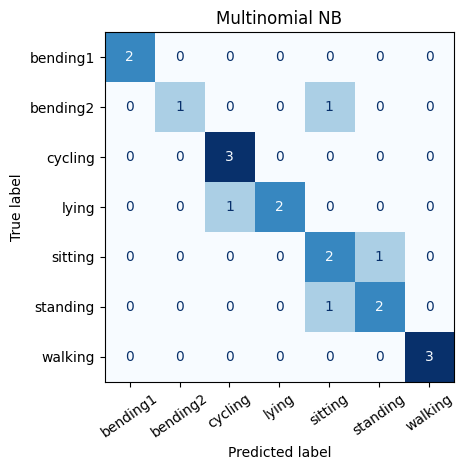

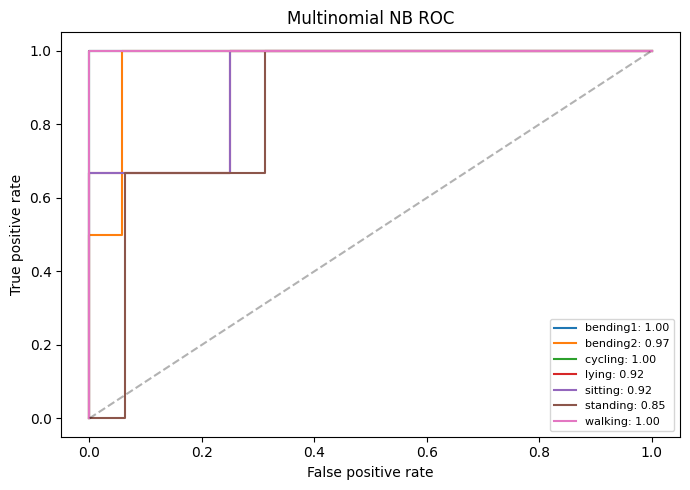

In [ ]:
def nb_model(name):
    return (make_pipeline(StandardScaler(),GaussianNB()) if name=='Gaussian NB'
            else make_pipeline(MinMaxScaler(),MultinomialNB()))

nb_best = {}
for name in ('Gaussian NB','Multinomial NB'):
    scores = [(l,cross_val_score(nb_model(name),X_train_by_l[l],y_train_multi,cv=cv).mean())
              for l in range(1,21)]
    l,cv_acc = sorted(scores,key=lambda x:(-x[1],x[0]))[0]
    model = nb_model(name).fit(X_train_by_l[l],y_train_multi)
    pred,probs = model.predict(X_test_by_l[l]),model.predict_proba(X_test_by_l[l])
    test_acc = accuracy_score(y_test_multi,pred)
    nb_best[name] = dict(l=l,cv_accuracy=cv_acc,test_accuracy=test_acc)
    print(f'{name}: l={l}, CV={cv_acc:.4f}, test error={1-test_acc:.4f}')
    plot_cm(y_test_multi,pred,ACTIVITIES,name)
    plot_roc(y_test_multi,probs,model.classes_,name+' ROC')

### 2(c)iii. Best Multiclass Method

In [ ]:
multi_compare = pd.DataFrame([
    ['Multinomial L1 logistic',int(best_multi.l),best_multi.cv_accuracy,acc_multi],
    *[(name,v['l'],v['cv_accuracy'],v['test_accuracy']) for name,v in nb_best.items()]
],columns=['Method','Best l','5-fold CV accuracy','Test accuracy'])
multi_compare['Test error'] = 1-multi_compare['Test accuracy']
display(multi_compare.round(4))
cv_winner = multi_compare.loc[multi_compare['5-fold CV accuracy'].idxmax(),'Method']
test_winner = multi_compare.loc[multi_compare['Test accuracy'].idxmax(),'Method']
print('Best CV:',cv_winner,'| Best test:',test_winner)
print('Answer:',cv_winner,'is preferred based on CV.')

,Method,Best l,5-fold CV accuracy,Test accuracy,Test error
0,Multinomial L1 logistic,1,0.8846,0.9474,0.0526
1,Gaussian NB,1,0.8989,0.8947,0.1053
2,Multinomial NB,5,0.7264,0.7895,0.2105


Best CV: Gaussian NB | Best test: Multinomial L1 logistic
Answer: Gaussian NB is preferred based on CV.


## 3. ISLR 4.8.3 — QDA

The discriminant is

$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Different variances make QDA quadratic. Equal variances cancel the quadratic terms.

## 4. ISLR 4.8.7 — Dividend Probability

In [ ]:
a = .8*np.exp(-(4-10)**2/72)
b = .2*np.exp(-4**2/72)
print(f'P(Yes | X=4) = {a/(a+b):.4f}')

P(Yes | X=4) = 0.7519


**Answer:** The probability is about 75.2%.

## References

- UCI AReM Dataset
- An Introduction to Statistical Learning (ISLR)
- Scikit-learn
- ChatGPT